# ITSM benchmark: reproducible data analysis

Task 3 deliverable for the **Machine Learning / AI** track. Run this notebook from the repository root with **Kernel → Restart & Run All**. The cells call the same processing and plotting modules used by the command-line pipeline.

> **Data status:** `data/sample/` and the checked-in benchmark run are synthetic demonstration data. They validate the workflow only; none of the values below are research findings about real companies or production systems.

## 1. Reproducible setup

The random seed is fixed at 42 for workload construction and bootstrap resampling. The raw JSONL starts with a metadata record followed by warm-up and evaluation records. Warm-ups are excluded; evaluation failures remain in the data and in the error-rate guardrail.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.benchmark import add_derived, load_cases
from src.process_data import aggregate_metrics, bootstrap_ci, load_benchmark_data, process_jsonl
from src.visualize import generate_figures

SEED = 42
BOOTSTRAP_SAMPLES = 2000
RAW_PATH = Path("data/raw/test_run.jsonl")
PROCESSED_DIR = Path("data/processed")
FIGURES_DIR = Path("reports/figures")
np.random.seed(SEED)
pd.set_option("display.max_columns", 20)
assert RAW_PATH.is_file(), f"Missing raw benchmark log: {RAW_PATH}"

## 2. Ingestion, warm-up filtering, and error guardrail

The parser validates the JSONL schema and phase labels. It removes only the `warmup` phase; error runs in the evaluation phase are preserved. The outlier rule flags successful latencies outside 1.5×IQR within a workload-size bin and does not delete any observation.

In [2]:
metadata, runs = load_benchmark_data(RAW_PATH)
print(f"Raw runs: {metadata['n_raw_runs']}")
print(f"Warm-up runs excluded: {metadata['n_warmup_runs']}")
print(f"Evaluation runs retained: {metadata['n_evaluation_runs']}")
print(f"Evaluation errors retained: {int(runs['status'].eq('error').sum())}")
print(f"Latency outliers flagged, not removed: {int(runs['latency_outlier'].sum())}")
runs.groupby(['phase', 'status'], dropna=False).size().rename('runs').to_frame()

Raw runs: 115
Warm-up runs excluded: 15
Evaluation runs retained: 100
Evaluation errors retained: 2
Latency outliers flagged, not removed: 15


runs
phase status       
work  error       2
      success    98

## 3. Statistical aggregation

For successful runs, report mean, sample standard deviation, median, p25/p75, p95 and p99 latency. Median, p95 and p99 confidence intervals use a seeded percentile bootstrap. Throughput is derived as processed cases per second, not offered ITSM requests per second. Every summary row also reports total runs, failures, expected invalid-input failures, and non-destructive outlier counts.

In [3]:
metadata, runs, summary, guardrails = process_jsonl(
    RAW_PATH,
    PROCESSED_DIR,
    bootstrap_samples=BOOTSTRAP_SAMPLES,
    seed=SEED,
)
overall = summary.loc[summary['workload_kind'].eq('ALL')].set_index('workload_kind')
display(overall.T.rename(columns={'ALL': 'All evaluation runs'}))
display(guardrails)
print(f"Saved {PROCESSED_DIR / 'metrics_summary.csv'}")
print(f"Saved {PROCESSED_DIR / 'benchmark_guardrails.csv'}")

workload_kind,All evaluation runs
load_bin,0.000000
n_runs,100.000000
n_success,98.000000
n_errors,2.000000
n_expected_errors,2.000000
n_unexpected_errors,0.000000
error_rate_pct,2.000000
unexpected_error_rate_pct,0.000000
n_outliers_flagged,15.000000
n_rows_min,0.000000


,guardrail,value,expected_errors_excluded_from_guardrail,total_evaluation_runs,unexpected_errors,threshold_pct,passed,note
0,Unexpected evaluation error rate (%),0.0,2,100,0,0.0,True,Expected invalid_zero_total edge-case errors r...


Saved data/processed/metrics_summary.csv
Saved data/processed/benchmark_guardrails.csv


## 4. Research-group comparison (synthetic sample only)

This small comparison reuses the Task 2 sample cases: C1 is the legacy baseline and E1 is the guardrailed hybrid method. Each result is shown as median (p25–p75), with a bootstrap 95% CI for the median. C1 has no paired handoff-time observations in the sample, so that comparison is reported as unavailable rather than imputed.

In [4]:
cases = add_derived(load_cases(Path('data/sample/cases.csv')))
metric_specs = {
    'HITL embedding score (1–5)': 'hitl_score',
    'Handoff reduction (%)': 'dT_handoff_pct',
    'Misrouting rate (%)': 'r_bounce_pct',
    'Governance index (0–3)': 'i_gov',
}
comparison_rows = []
for label, column in metric_specs.items():
    for group, group_label in [('C1', 'Baseline (C1)'), ('E1', 'Proposed (E1)')]:
        values = cases.loc[cases['group'].eq(group), column].dropna().to_numpy(dtype=float)
        if len(values):
            low, high = bootstrap_ci(values, resamples=BOOTSTRAP_SAMPLES, seed=SEED + len(comparison_rows))
            result = {
                'Metric': label,
                'Method': group_label,
                'n': len(values),
                'Median (p25–p75)': f"{np.median(values):.2f} ({np.percentile(values, 25):.2f}–{np.percentile(values, 75):.2f})",
                'Bootstrap 95% CI for median': f"({low:.2f}, {high:.2f})",
            }
        else:
            result = {
                'Metric': label,
                'Method': group_label,
                'n': 0,
                'Median (p25–p75)': 'Not available',
                'Bootstrap 95% CI for median': 'Not available',
            }
        comparison_rows.append(result)
comparison = pd.DataFrame(comparison_rows)
display(comparison)

,Metric,Method,n,Median (p25–p75),Bootstrap 95% CI for median
0,HITL embedding score (1–5),Baseline (C1),4,1.50 (1.00–2.00),"(1.00, 2.00)"
1,HITL embedding score (1–5),Proposed (E1),4,4.00 (4.00–4.25),"(4.00, 5.00)"
2,Handoff reduction (%),Baseline (C1),0,Not available,Not available
3,Handoff reduction (%),Proposed (E1),4,53.59 (51.64–54.81),"(46.55, 57.69)"
4,Misrouting rate (%),Baseline (C1),4,15.83 (14.89–17.00),"(14.55, 18.00)"
5,Misrouting rate (%),Proposed (E1),4,5.78 (5.48–6.17),"(5.26, 6.67)"
6,Governance index (0–3),Baseline (C1),4,1.50 (0.75–2.00),"(0.00, 2.00)"
7,Governance index (0–3),Proposed (E1),4,3.00 (2.75–3.00),"(2.00, 3.00)"


## 5. Scientific figures

Figure 1 plots latency percentiles against input size (cases per analysis call); this workload does not control or measure requests per second. Figure 2 shows successful-run latency distributions by synthetic workload shape. Both figures use explicit units, colorblind-safe colors, distinguishable markers/line styles, uncertainty intervals, vector PDF, and 300-DPI PNG exports.

Saved reports/figures/fig1_latency_vs_load.pdf and reports/figures/fig1_latency_vs_load.png


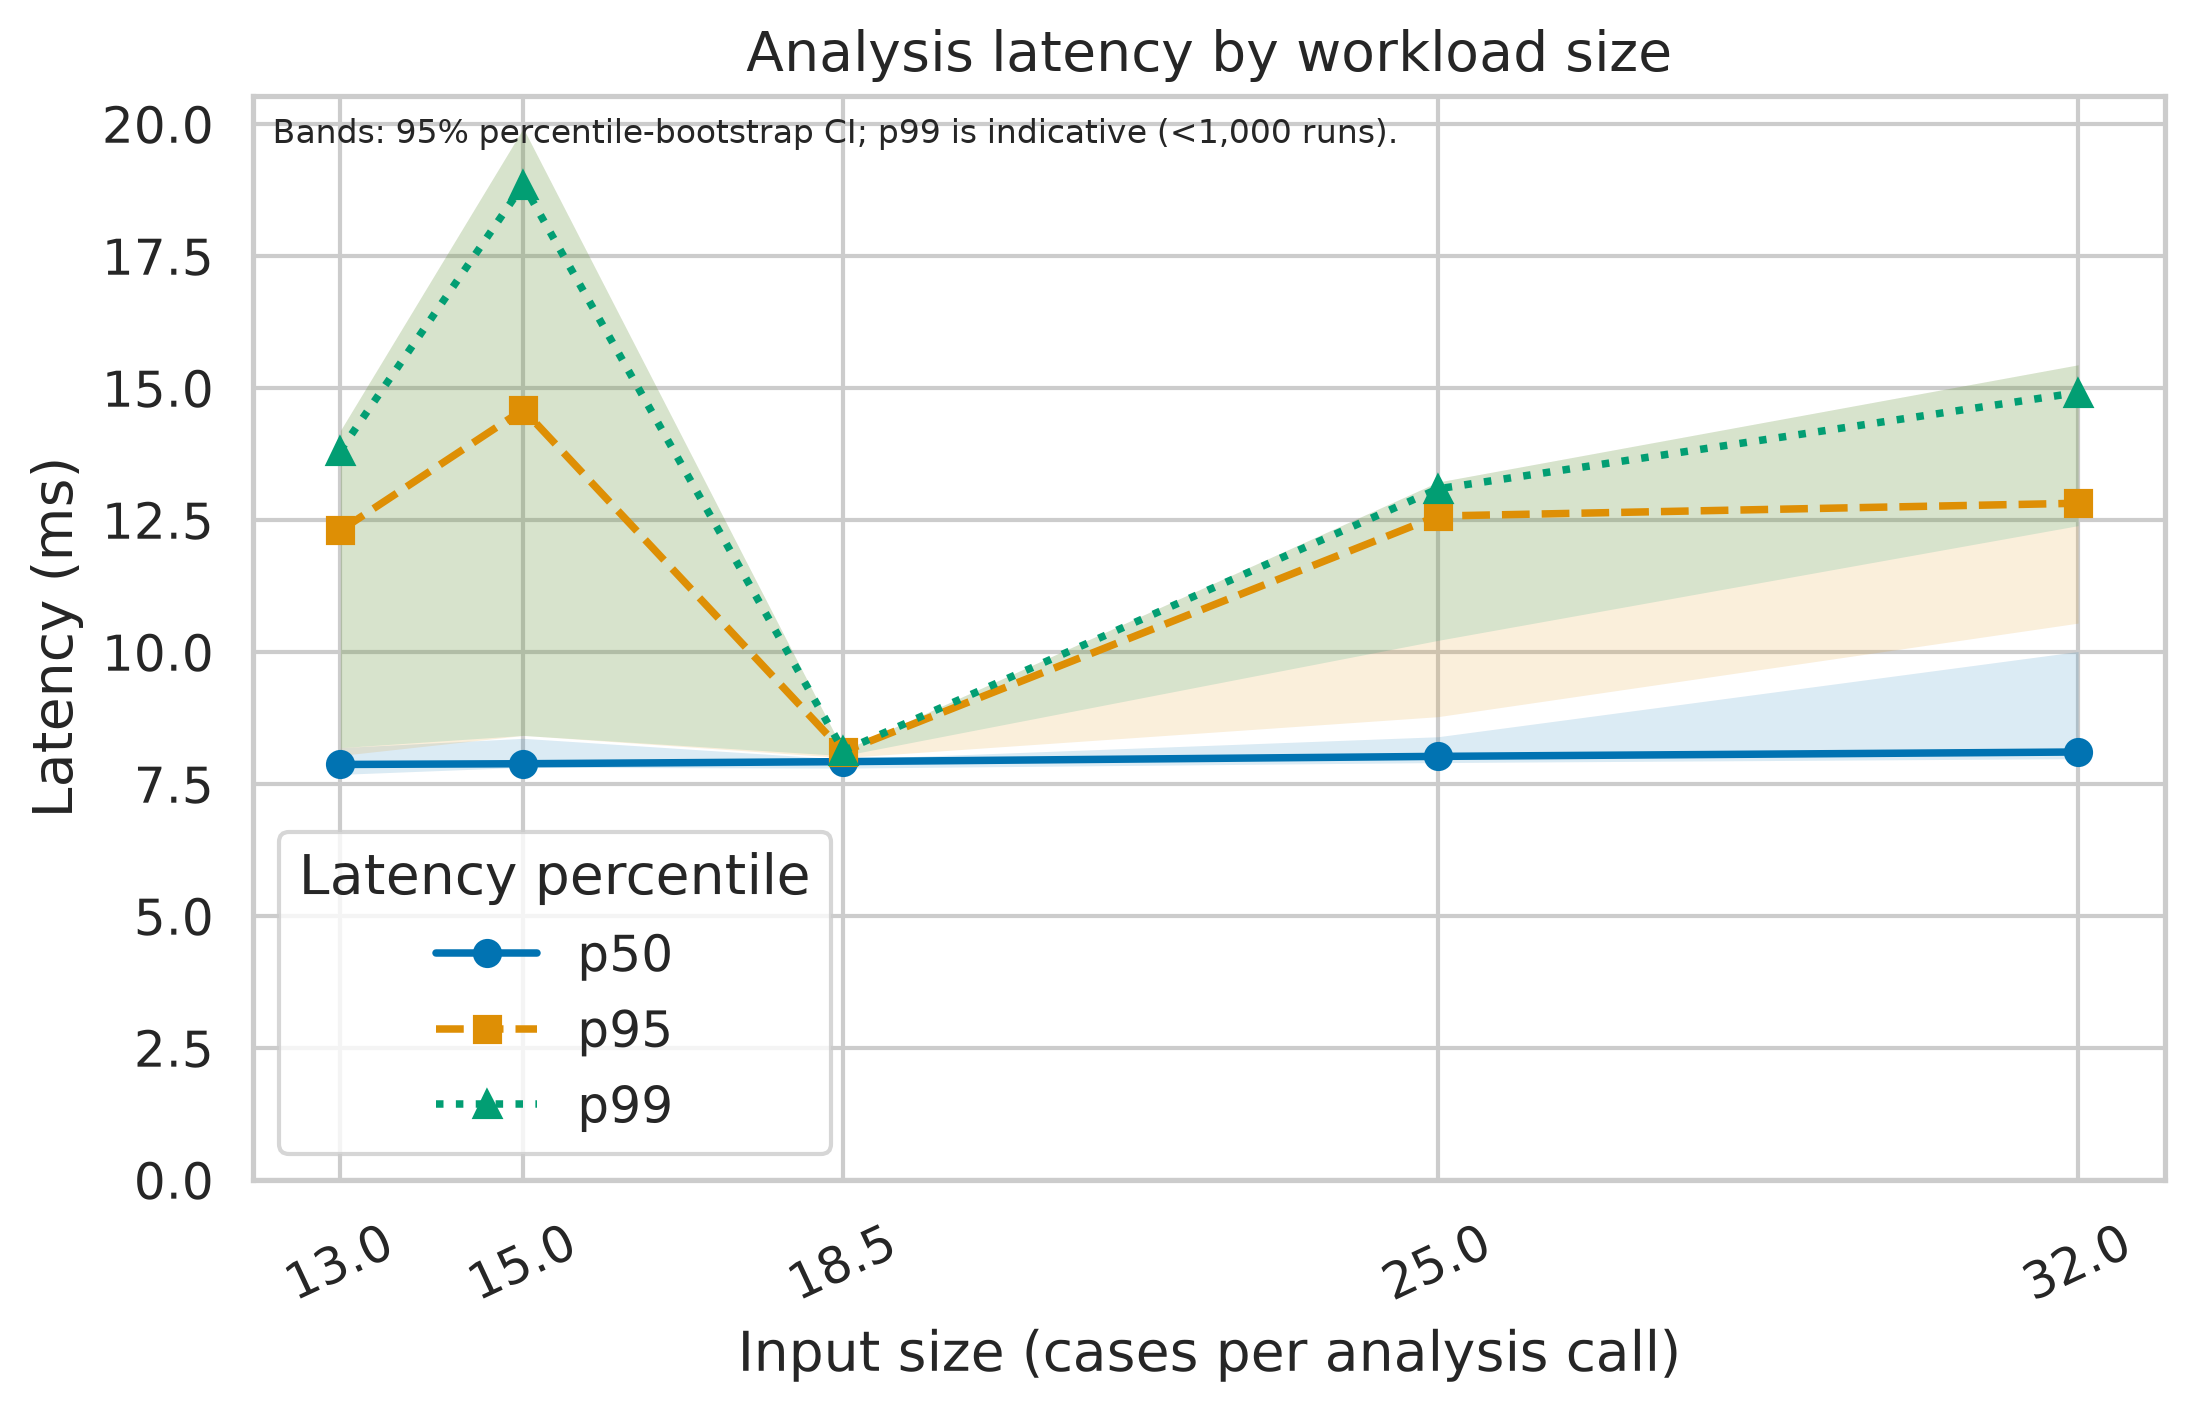

Saved reports/figures/fig2_distribution_boxplot.pdf and reports/figures/fig2_distribution_boxplot.png


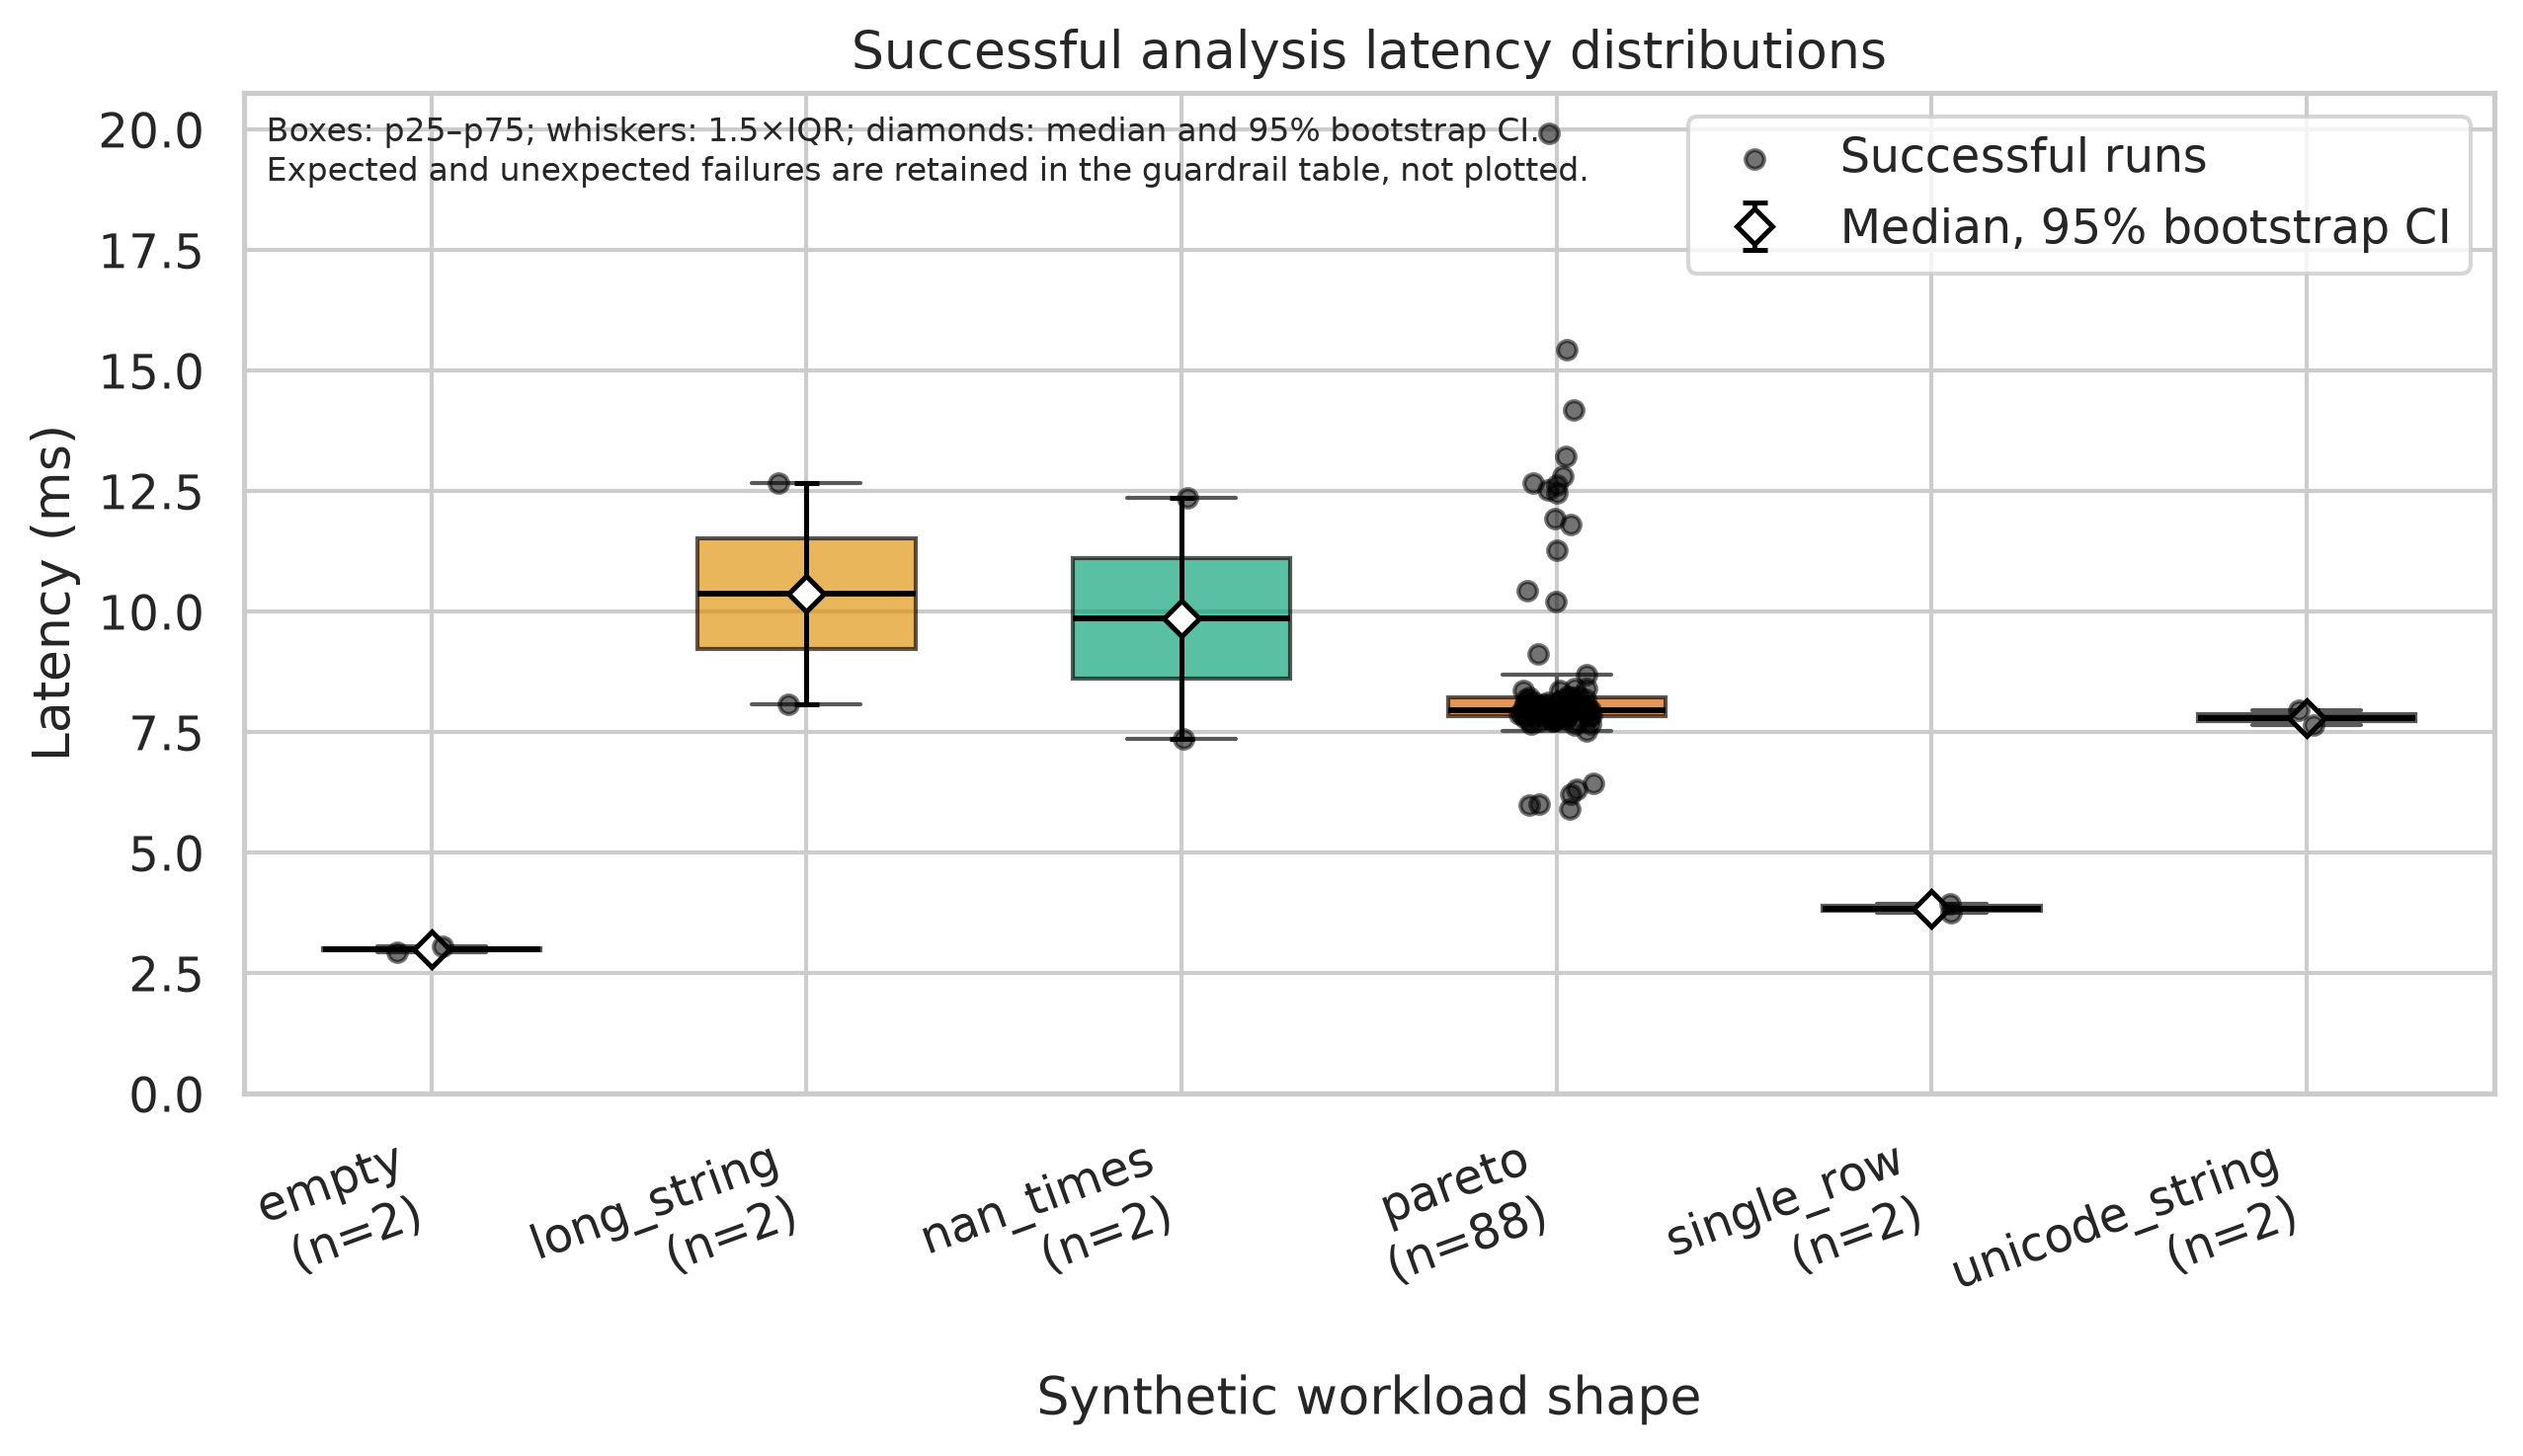

In [5]:
figure_paths = generate_figures(
    runs,
    summary,
    FIGURES_DIR,
    bootstrap_samples=BOOTSTRAP_SAMPLES,
    seed=SEED,
)
for pdf_path, png_path in figure_paths:
    print(f"Saved {pdf_path} and {png_path}")
    display(Image(filename=str(png_path)))

## 6. Interpretation and limits

These outputs verify the analysis workflow on synthetic cases and local Python execution timings. They are not evidence of production ITSM performance. The run loop measures one synchronous Python analysis call; it does not apply a controlled request rate, concurrency, network traffic, or two runtime implementations. Accordingly, the latency plot uses input cases rather than RPS, and the C1/E1 table is explicitly a synthetic research-group example. The p99 estimate is indicative because the evaluation set is small.